# Графики как обзор данных

In [ ]:
%pip -q install openpyxl

from pathlib import Path
import textwrap
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.ticker import PercentFormatter, MaxNLocator
from matplotlib.colors import ListedColormap

In [ ]:
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data/eurovision_features.xlsx").is_file())
PATH = ROOT / "data/eurovision_features.xlsx"
OUT = ROOT / "results/generated/data_overview"
OUT.mkdir(parents=True, exist_ok=True)

assert PATH.exists(), f"Загрузите файл в {PATH}"

book = pd.read_excel(PATH, sheet_name=None, engine="openpyxl")

A = book["A Топ-10"].copy()
B = book["B Зрители и жюри"].copy()
C = book["C Национальное голосование"].copy()
M = book["A С рынком"].copy()

BLUE, TEAL, ORANGE = "#3569B8", "#168B83", "#D58A35"
INK, GRAY, GRID = "#203047", "#65758A", "#E5EAF1"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "text.color": INK,
    "axes.labelcolor": INK,
    "xtick.color": GRAY,
    "ytick.color": GRAY,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.edgecolor": GRID,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.axisbelow": True,
    "figure.dpi": 120,
    "savefig.facecolor": "white",
    "pdf.fonttype": 42,
})

NAMES = {
    "AL": "Албания", "AM": "Армения", "AT": "Австрия",
    "AU": "Австралия", "AZ": "Азербайджан",
    "BA": "Босния и Герцеговина", "BE": "Бельгия",
    "BG": "Болгария", "BY": "Беларусь", "CH": "Швейцария",
    "CY": "Кипр", "CZ": "Чехия", "DE": "Германия",
    "DK": "Дания", "EE": "Эстония", "ES": "Испания",
    "FI": "Финляндия", "FR": "Франция",
    "GB": "Великобритания", "GE": "Грузия", "GR": "Греция",
    "HR": "Хорватия", "HU": "Венгрия", "IE": "Ирландия",
    "IL": "Израиль", "IS": "Исландия", "IT": "Италия",
    "LT": "Литва", "LU": "Люксембург", "LV": "Латвия",
    "MD": "Молдова", "ME": "Черногория",
    "MK": "Сев. Македония", "MT": "Мальта",
    "NL": "Нидерланды", "NO": "Норвегия", "PL": "Польша",
    "PT": "Португалия", "RO": "Румыния", "RS": "Сербия",
    "RU": "Россия", "SE": "Швеция", "SI": "Словения",
    "SK": "Словакия", "SM": "Сан-Марино",
    "TR": "Турция", "UA": "Украина",
}

for df in (A, B, C, M):
    df["year"] = pd.to_numeric(df["year"], errors="raise").astype(int)

assert not A.duplicated(["year", "country"]).any()
assert not B.duplicated(["year", "country"]).any()
assert not C.duplicated(["year", "voter", "recipient"]).any()

# В каждом национальном голосовании — один победитель
# и полный набор допустимых кандидатов.
assert (
    C.groupby(["year", "voter"])["target_first_place"].sum() == 1
).all()

assert (
    C.groupby(["year", "voter"]).size()
    == C.groupby(["year", "voter"])["candidate_count"].first()
).all()


def finish(fig, filename, title, subtitle, note, **layout):
    """Единые заголовки, отступы, сохранение и показ."""
    defaults = dict(
        left=.10, right=.97, bottom=.21, top=.81, wspace=.40
    )
    defaults.update(layout)
    fig.subplots_adjust(**defaults)

    fig.suptitle(
        title, x=.035, y=.98, ha="left",
        fontsize=20, weight="bold"
    )
    fig.text(
        .035, .91, textwrap.fill(subtitle, 132),
        fontsize=11, color=GRAY,
        ha="left", va="top", linespacing=1.4
    )
    fig.text(
        .035, .025, textwrap.fill(note, 147),
        fontsize=9, color=GRAY,
        ha="left", va="bottom", linespacing=1.4
    )

    for extension in ("png", "pdf"):
        fig.savefig(
            OUT / f"{filename}.{extension}",
            dpi=240, bbox_inches="tight", pad_inches=.18
        )

    plt.show()
    plt.close(fig)


def rates_by_year(df, group, target, order, seed=2026, draws=3000):
    """Частоты и bootstrap-интервалы: пересэмплируем целые годы."""
    stats = (
        df.groupby(["year", group], observed=True)[target]
        .agg(["sum", "count"])
    )
    years = np.sort(df["year"].unique())

    def matrix(field):
        return (
            stats[field]
            .unstack(group)
            .reindex(index=years, columns=order)
            .fillna(0)
            .to_numpy(float)
        )

    successes, counts = matrix("sum"), matrix("count")

    weights = np.random.default_rng(seed).multinomial(
        len(years),
        np.full(len(years), 1 / len(years)),
        size=draws
    )

    denominator = weights @ counts
    simulations = np.divide(
        weights @ successes,
        denominator,
        out=np.full(denominator.shape, np.nan),
        where=denominator > 0
    )

    lo, hi = np.nanquantile(simulations, [.025, .975], axis=0)

    return pd.DataFrame({
        "rate": successes.sum(0) / counts.sum(0),
        "lo": lo,
        "hi": hi,
        "n": counts.sum(0).astype(int),
    }, index=order)


def frequency_bars(ax, stats, labels, color=BLUE, baseline=None):
    """Столбцы с интервалами, процентами и числом наблюдений."""
    x = np.arange(len(stats))

    ax.bar(
        x, stats["rate"], width=.59,
        color=color, alpha=.88, zorder=2
    )
    ax.vlines(
        x, stats["lo"], stats["hi"],
        color=INK, linewidth=1.5, zorder=3
    )
    for column in ("lo", "hi"):
        ax.hlines(
            stats[column], x-.065, x+.065,
            color=INK, linewidth=1.5
        )

    upper = min(1.05, max(
        .08,
        stats["hi"].max() * 1.28,
        baseline * 1.35 if baseline is not None else 0
    ))

    for i, row in enumerate(stats.itertuples()):
        ax.text(
            i, row.hi + .025 * upper,
            f"{row.rate:.1%}",
            ha="center", fontsize=12,
            weight="bold", color=INK
        )

    if baseline is not None:
        ax.axhline(
            baseline, color=GRAY,
            ls=(0, (4, 4)), linewidth=1.3
        )

    ax.set_xticks(x)
    ax.set_xticklabels([
        f"{label}\nn = {n:,}".replace(",", " ")
        for label, n in zip(labels, stats["n"])
    ], fontsize=11)

    ax.set_ylim(0, upper)
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.grid(axis="y", color=GRID)


print(
    f"A: {len(A)} финалистов; B: {len(B)}; "
    f"C: {C.groupby(['year', 'voter']).ngroups} голосований "
    f"/ {len(C)} пар."
)

A: 437 финалистов; B: 232; C: 349 голосований / 8770 пар.


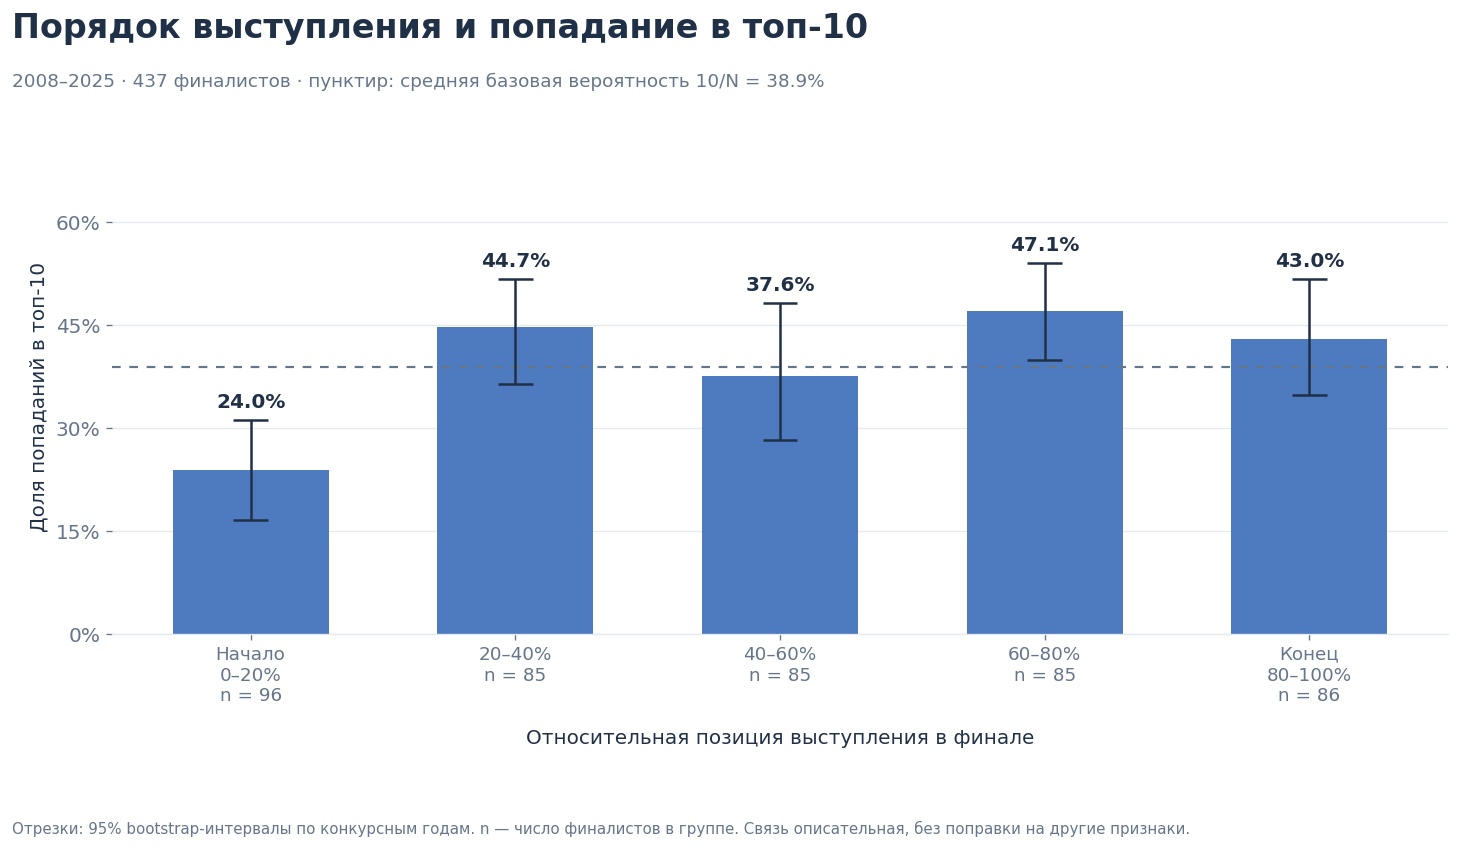

In [ ]:
position = A.assign(
    position_bin=pd.cut(
        A["running_position"],
        np.linspace(0, 1, 6),
        labels=False,
        include_lowest=True
    )
)

stats = rates_by_year(
    position, "position_bin", "target_top10", list(range(5))
)
baseline = (10 / A["n_finalists"]).mean()

fig, ax = plt.subplots(figsize=(12.8, 7.2))

frequency_bars(
    ax, stats,
    [
        "Начало\n0–20%",
        "20–40%",
        "40–60%",
        "60–80%",
        "Конец\n80–100%"
    ],
    baseline=baseline
)

ax.set_ylabel("Доля попаданий в топ-10")
ax.set_xlabel(
    "Относительная позиция выступления в финале",
    labelpad=14
)

finish(
    fig,
    "01_running_order",
    "Порядок выступления и попадание в топ-10",
    f"{A.year.min()}–{A.year.max()} · {len(A)} финалистов · "
    f"пунктир: средняя базовая вероятность 10/N = {baseline:.1%}",
    "Отрезки: 95% bootstrap-интервалы по конкурсным годам. "
    "n — число финалистов в группе. "
    "Связь описательная, без поправки на другие признаки.",
    bottom=.26
)

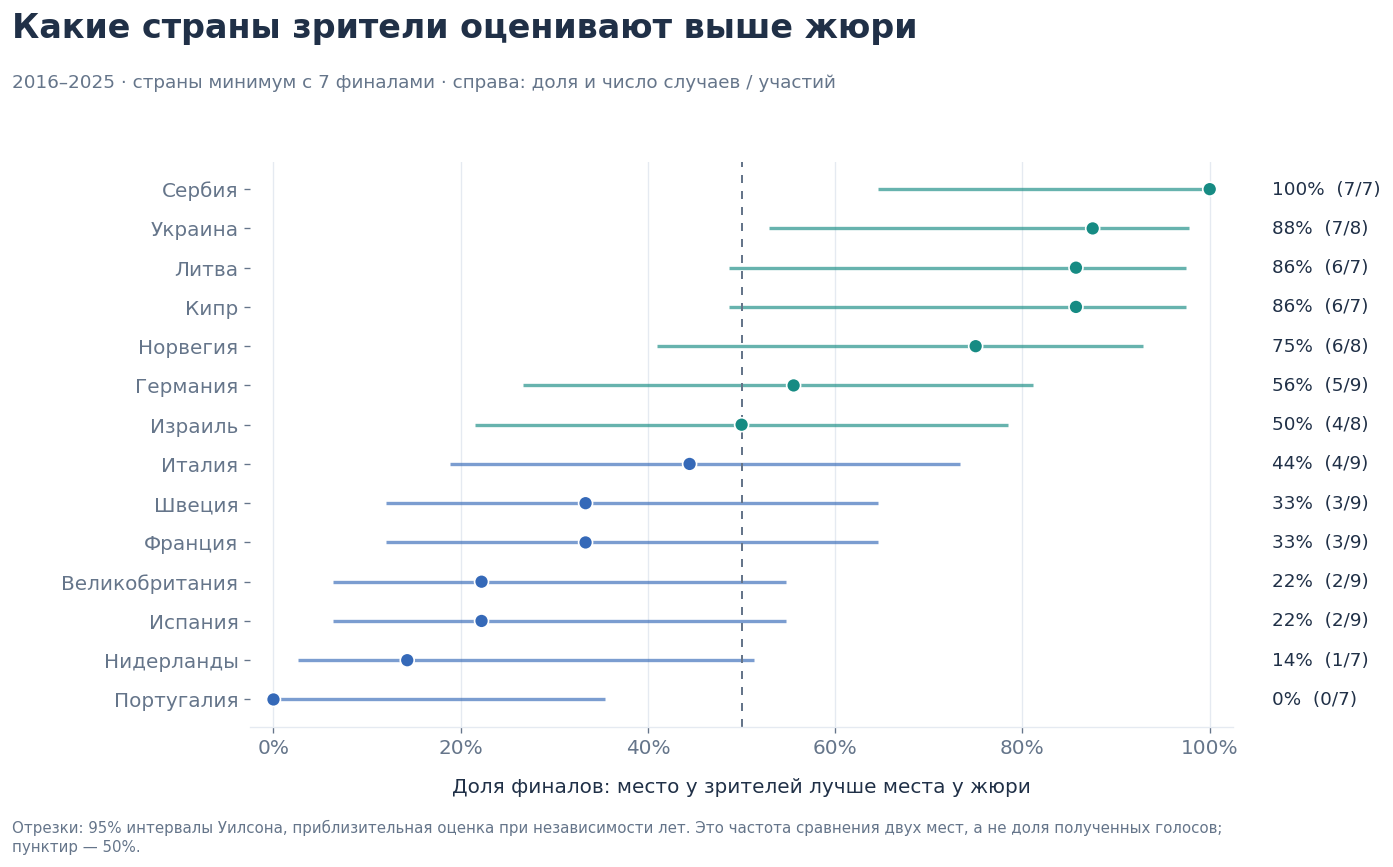

In [ ]:
MIN_FINALS = 7

country = (
    B.groupby("country")["target_audience_above_jury"]
    .agg(wins="sum", n="size")
)
country = country.loc[country.n >= MIN_FINALS].copy()

assert len(country), "Уменьшите MIN_FINALS."

country["rate"] = country.wins / country.n

# 95% интервалы Уилсона: корректно ведут себя при 0/n и n/n.
z = 1.96
den = 1 + z*z / country.n
center = (country.rate + z*z / (2*country.n)) / den
half = z * np.sqrt(
    country.rate * (1-country.rate) / country.n
    + z*z / (4*country.n**2)
) / den

country["lo"] = center - half
country["hi"] = center + half
country = country.sort_values(["rate", "n"], kind="stable")

y = np.arange(len(country))
colors = [TEAL if p >= .5 else BLUE for p in country.rate]

fig, ax = plt.subplots(
    figsize=(12.8, max(7.2, 2.6 + .34*len(country)))
)

ax.hlines(
    y, country.lo, country.hi,
    color=colors, linewidth=2, alpha=.65
)
ax.scatter(
    country.rate, y, s=70,
    c=colors, edgecolor="white", zorder=3
)
ax.axvline(.5, color=GRAY, ls=(0, (4, 4)), linewidth=1.2)

ax.set_yticks(y)
ax.set_yticklabels([NAMES.get(c, c) for c in country.index])

for i, row in enumerate(country.itertuples()):
    ax.text(
        1.04, i,
        f"{row.rate:.0%}  ({int(row.wins)}/{int(row.n)})",
        transform=ax.get_yaxis_transform(),
        va="center", fontsize=11
    )

ax.set_xlim(-.025, 1.025)
ax.set_ylim(-.7, len(country)-.3)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel(
    "Доля финалов: место у зрителей лучше места у жюри",
    labelpad=12
)
ax.grid(axis="x", color=GRID)

finish(
    fig,
    "02_audience_vs_jury",
    "Какие страны зрители оценивают выше жюри",
    f"{B.year.min()}–{B.year.max()} · "
    f"страны минимум с {MIN_FINALS} финалами · "
    "справа: доля и число случаев / участий",
    "Отрезки: 95% интервалы Уилсона, приблизительная оценка "
    "при независимости лет. Это частота сравнения двух мест, "
    "а не доля полученных голосов; пунктир — 50%.",
    left=.19, right=.83, bottom=.17
)

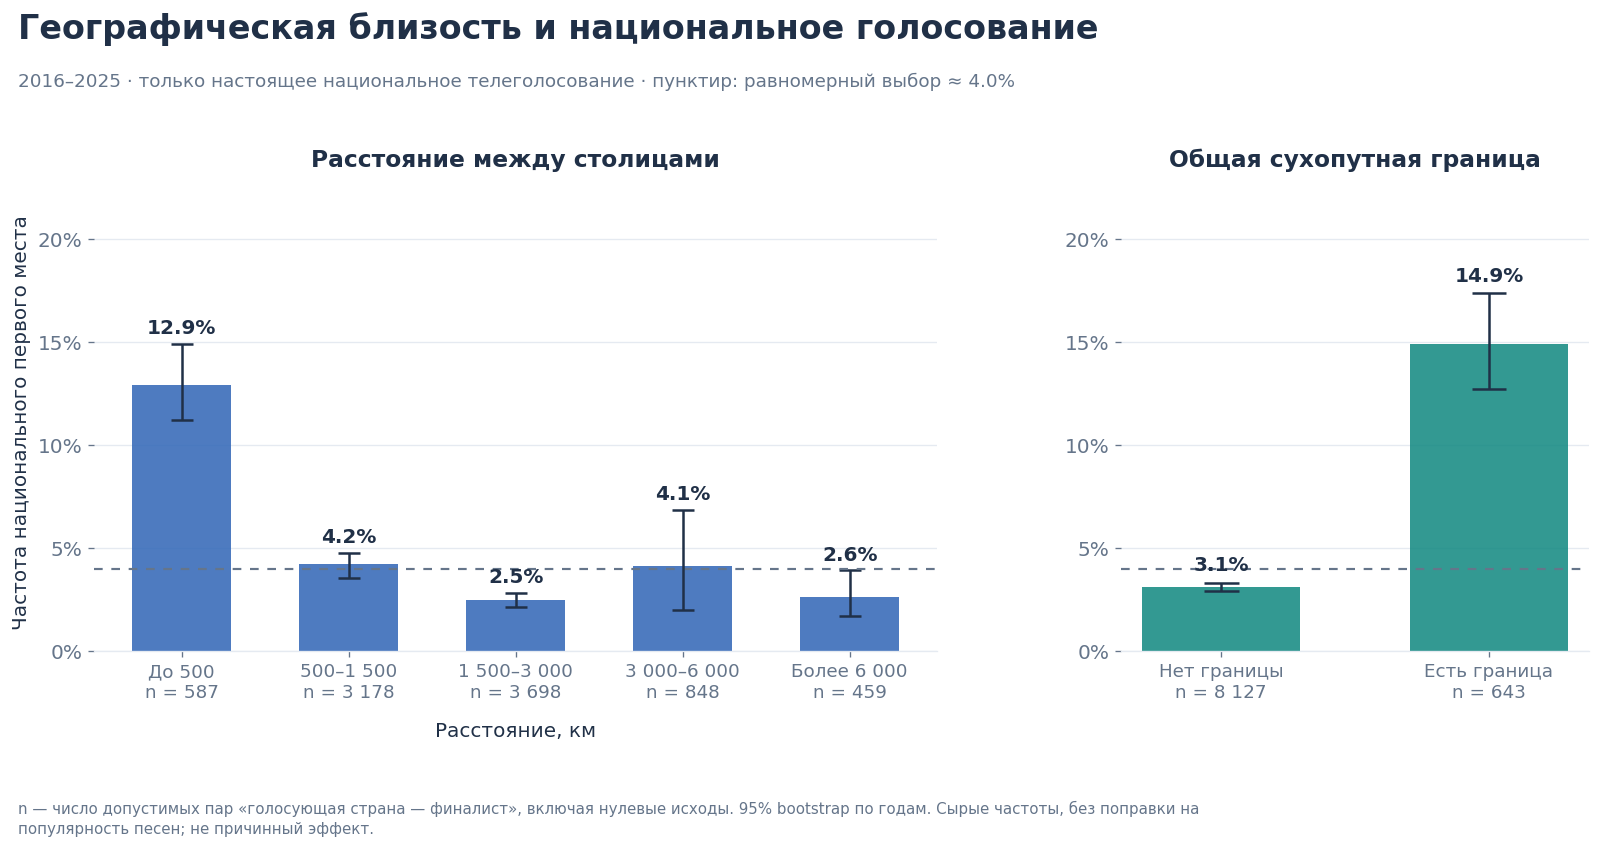

In [ ]:
geo = C.copy()

# Восстанавливаем километры из log(1 + distance_km).
geo["distance_km"] = np.expm1(geo["log_distance"])

edges = [0, 500, 1500, 3000, 6000, np.inf]
geo["distance_bin"] = pd.cut(
    geo.distance_km,
    edges,
    labels=False,
    include_lowest=True
)

distance_stats = rates_by_year(
    geo, "distance_bin", "target_first_place", list(range(5))
)
border_stats = rates_by_year(
    geo, "shared_border", "target_first_place", [0, 1]
)

neutral = (1 / geo.candidate_count).mean()

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 7.2),
    gridspec_kw={"width_ratios": [1.8, 1]}
)

frequency_bars(
    axes[0],
    distance_stats,
    [
        "До 500",
        "500–1 500",
        "1 500–3 000",
        "3 000–6 000",
        "Более 6 000"
    ],
    baseline=neutral
)
frequency_bars(
    axes[1],
    border_stats,
    ["Нет границы", "Есть граница"],
    color=TEAL,
    baseline=neutral
)

# Одинаковая вертикальная шкала для двух панелей.
common_top = max(ax.get_ylim()[1] for ax in axes)
for ax in axes:
    ax.set_ylim(0, common_top)

axes[0].set_title(
    "Расстояние между столицами", pad=16, weight="bold"
)
axes[1].set_title(
    "Общая сухопутная граница", pad=16, weight="bold"
)
axes[0].set_xlabel("Расстояние, км", labelpad=12)
axes[0].set_ylabel("Частота национального первого места")

finish(
    fig,
    "03_geography",
    "Географическая близость и национальное голосование",
    f"{C.year.min()}–{C.year.max()} · "
    "только настоящее национальное телеголосование · "
    f"пунктир: равномерный выбор ≈ {neutral:.1%}",
    "n — число допустимых пар «голосующая страна — финалист», "
    "включая нулевые исходы. 95% bootstrap по годам. "
    "Сырые частоты, без поправки на популярность песен; "
    "не причинный эффект.",
    left=.08, wspace=.28, top=.77, bottom=.24
)

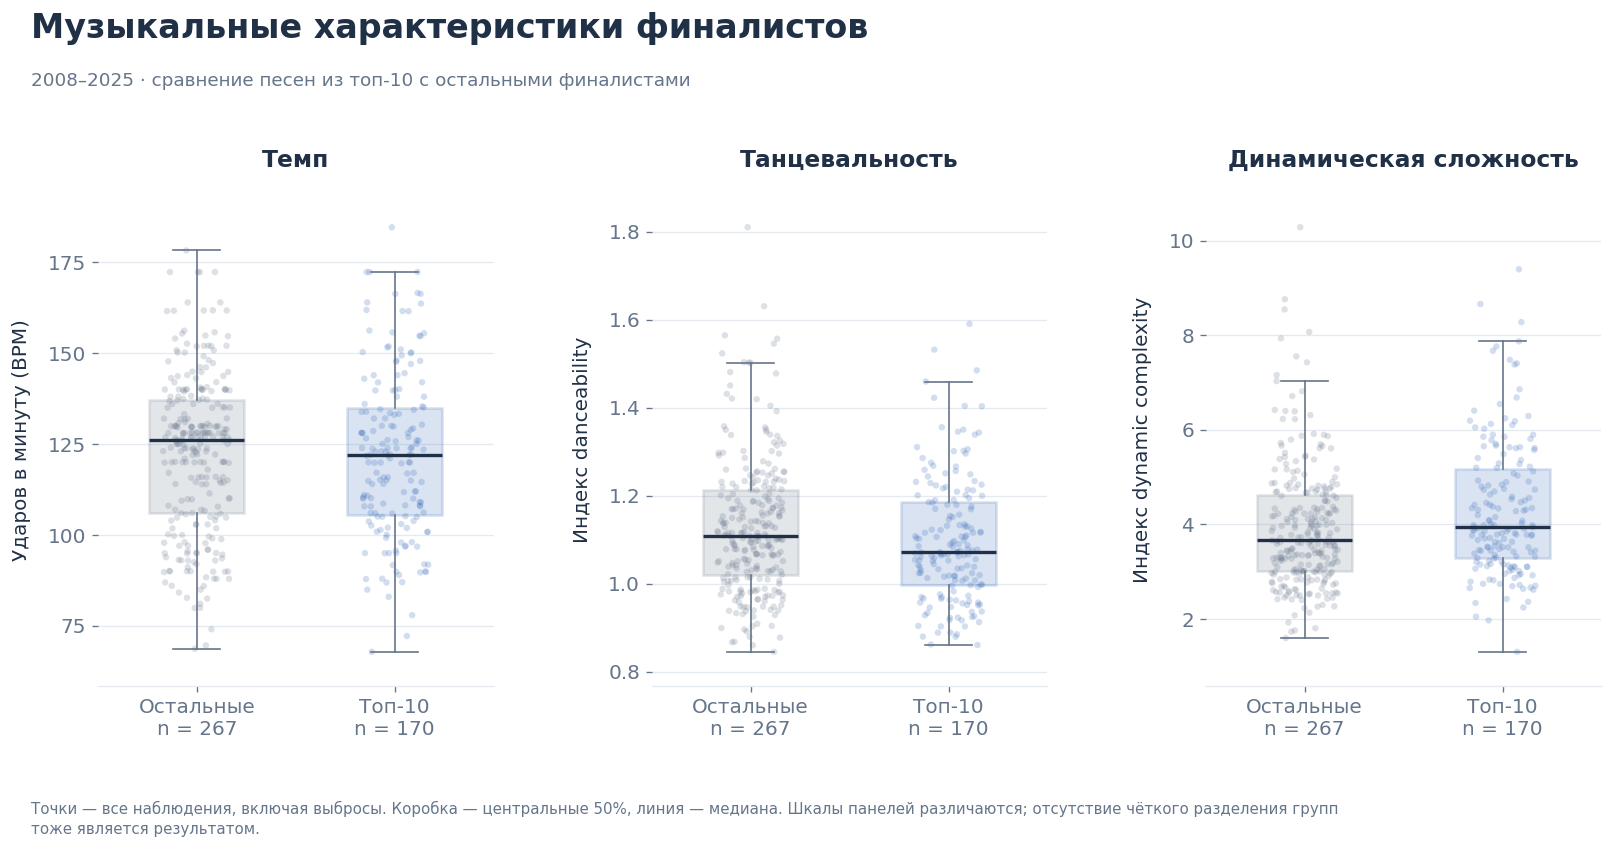

In [ ]:
features = [
    ("bpm", "Темп", "Ударов в минуту (BPM)"),
    ("danceability", "Танцевальность", "Индекс danceability"),
    (
        "dynamic_complexity",
        "Динамическая сложность",
        "Индекс dynamic complexity"
    ),
]

assert A[[c for c, _, _ in features]].notna().all().all()

rng = np.random.default_rng(2026)
fig, axes = plt.subplots(1, 3, figsize=(14, 7.2))

for ax, (column, title, ylabel) in zip(axes, features):
    groups = [
        A.loc[A.target_top10 == flag, column].to_numpy(float)
        for flag in [0, 1]
    ]

    # Показываем все песни, включая выбросы.
    for i, (values, color) in enumerate(
        zip(groups, [GRAY, BLUE]), 1
    ):
        ax.scatter(
            i + rng.uniform(-.17, .17, len(values)),
            values,
            s=15, alpha=.22,
            color=color, edgecolors="none", zorder=2
        )

    boxes = ax.boxplot(
        groups,
        positions=[1, 2],
        widths=.48,
        patch_artist=True,
        showfliers=False,
        medianprops={"color": INK, "linewidth": 2},
        whiskerprops={"color": GRAY},
        capprops={"color": GRAY}
    )

    for box, color in zip(boxes["boxes"], [GRAY, BLUE]):
        box.set(
            facecolor=color, alpha=.18,
            edgecolor=color, linewidth=1.6
        )

    ax.set_xticks([1, 2])
    ax.set_xticklabels([
        f"Остальные\nn = {len(groups[0])}",
        f"Топ-10\nn = {len(groups[1])}"
    ])
    ax.set_title(title, weight="bold", pad=16)
    ax.set_ylabel(ylabel, labelpad=10)

    values = np.concatenate(groups)
    padding = .08 * np.ptp(values)
    ax.set_ylim(values.min()-padding, values.max()+padding)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.grid(axis="y", color=GRID)

finish(
    fig,
    "04_audio_features",
    "Музыкальные характеристики финалистов",
    f"{A.year.min()}–{A.year.max()} · "
    "сравнение песен из топ-10 с остальными финалистами",
    "Точки — все наблюдения, включая выбросы. "
    "Коробка — центральные 50%, линия — медиана. "
    "Шкалы панелей различаются; отсутствие чёткого разделения "
    "групп тоже является результатом.",
    left=.075, wspace=.40, top=.77, bottom=.20
)

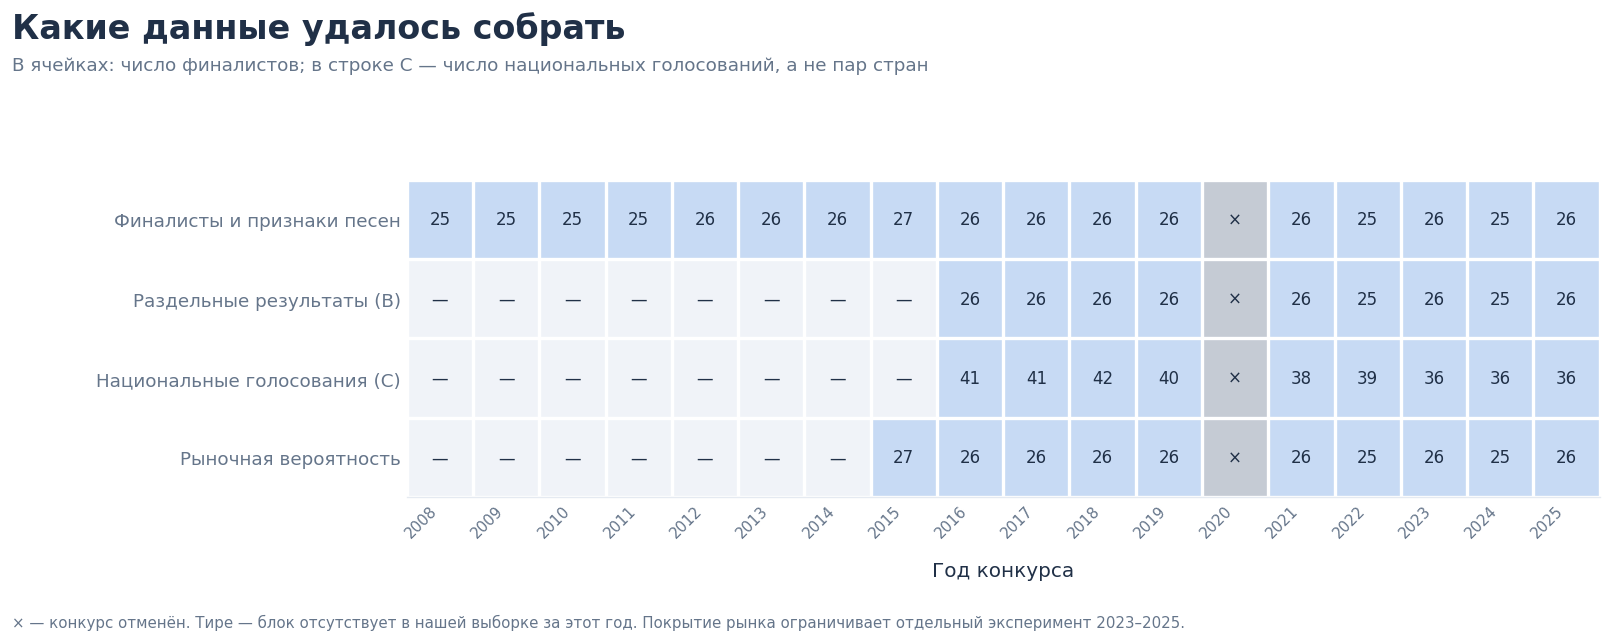

In [ ]:
years = np.arange(A.year.min(), A.year.max()+1)

coverage = pd.DataFrame({
    "Финалисты и признаки песен":
        A.groupby("year").size(),

    "Раздельные результаты (B)":
        B.groupby("year").size(),

    "Национальные голосования (C)":
        C[["year", "voter"]]
        .drop_duplicates()
        .groupby("year")
        .size(),

    "Рыночная вероятность":
        M.groupby("year").size(),
}).reindex(years).fillna(0).astype(int).T

status = (coverage.to_numpy() > 0).astype(int)

if 2020 in years:
    status[:, list(years).index(2020)] = 2

fig, ax = plt.subplots(figsize=(14, 5.4))

ax.imshow(
    status,
    cmap=ListedColormap(["#F0F3F8", "#C7DAF4", "#C5CBD4"]),
    vmin=0, vmax=2, aspect="auto"
)

for r in range(len(coverage)):
    for c in range(len(years)):
        value = coverage.iloc[r, c]
        label = (
            "×" if years[c] == 2020
            else str(value) if value
            else "—"
        )
        ax.text(
            c, r, label,
            ha="center", va="center",
            fontsize=10, color=INK
        )

ax.set_xticks(np.arange(len(years)))
ax.set_xticklabels(years, fontsize=9, rotation=45, ha="right")
ax.set_yticks(np.arange(len(coverage)))
ax.set_yticklabels(coverage.index, fontsize=11)

ax.set_xticks(np.arange(-.5, len(years), 1), minor=True)
ax.set_yticks(np.arange(-.5, len(coverage), 1), minor=True)
ax.grid(False)
ax.grid(which="minor", color="white", linewidth=2)
ax.tick_params(which="both", length=0)
ax.set_xlabel("Год конкурса", labelpad=12)

finish(
    fig,
    "05_coverage",
    "Какие данные удалось собрать",
    "В ячейках: число финалистов; "
    "в строке C — число национальных голосований, а не пар стран",
    "× — конкурс отменён. "
    "Тире — блок отсутствует в нашей выборке за этот год. "
    "Покрытие рынка ограничивает отдельный эксперимент 2023–2025.",
    left=.27, right=.98, top=.72, bottom=.23
)

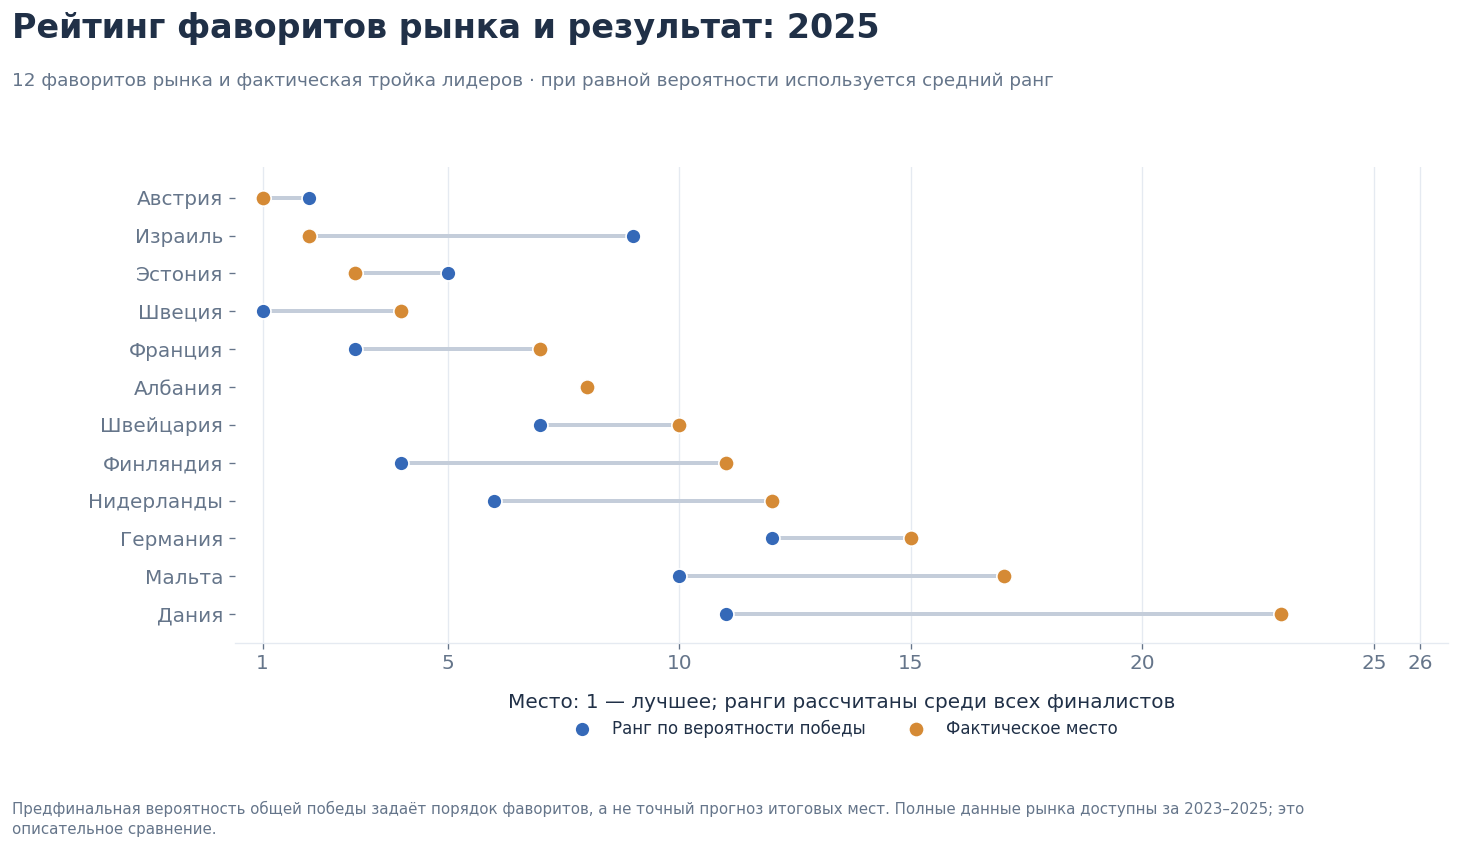

In [ ]:
YEAR = 2025
TOP_N = 12

market = M.loc[M.year == YEAR].copy()
assert len(market), f"Нет рыночных данных за {YEAR}."

# Равные вероятности получают одинаковый средний ранг.
market["market_rank"] = market.p_market.rank(
    ascending=False, method="average"
)

# Показываем фаворитов и обязательно фактическую тройку лидеров.
selected = set(market.nlargest(TOP_N, "p_market").country)
selected |= set(market.nsmallest(3, "place_final").country)

shown = (
    market.loc[market.country.isin(selected)]
    .sort_values("place_final", ascending=False)
)

y = np.arange(len(shown))

fig, ax = plt.subplots(
    figsize=(12.8, max(7.2, 2.8 + .36*len(shown)))
)

ax.hlines(
    y, shown.market_rank, shown.place_final,
    color="#C4CDDA", linewidth=2.4
)
ax.scatter(
    shown.market_rank, y,
    s=80, color=BLUE, edgecolor="white",
    label="Ранг по вероятности победы", zorder=3
)
ax.scatter(
    shown.place_final, y,
    s=85, color=ORANGE, edgecolor="white",
    label="Фактическое место", zorder=4
)

ax.set_yticks(y)
ax.set_yticklabels([NAMES.get(c, c) for c in shown.country])

ticks = [1] + list(range(5, len(market)+1, 5))
if len(market) % 5:
    ticks.append(len(market))

ax.set_xticks(ticks)
ax.set_xlim(.4, len(market)+.6)
ax.set_ylim(-.75, len(shown)-.2)
ax.set_xlabel(
    "Место: 1 — лучшее; ранги рассчитаны среди всех финалистов",
    labelpad=12
)
ax.grid(axis="x", color=GRID)
ax.legend(
    loc="upper center",
    bbox_to_anchor=(.5, -.13),
    ncol=2, frameon=False,
    fontsize=10, columnspacing=2
)

finish(
    fig,
    "06_market_vs_result",
    f"Рейтинг фаворитов рынка и результат: {YEAR}",
    f"{min(TOP_N, len(market))} фаворитов рынка "
    "и фактическая тройка лидеров · "
    "при равной вероятности используется средний ранг",
    "Предфинальная вероятность общей победы задаёт порядок "
    "фаворитов, а не точный прогноз итоговых мест. "
    "Полные данные рынка доступны за 2023–2025; "
    "это описательное сравнение.",
    left=.18, top=.80, bottom=.25
)

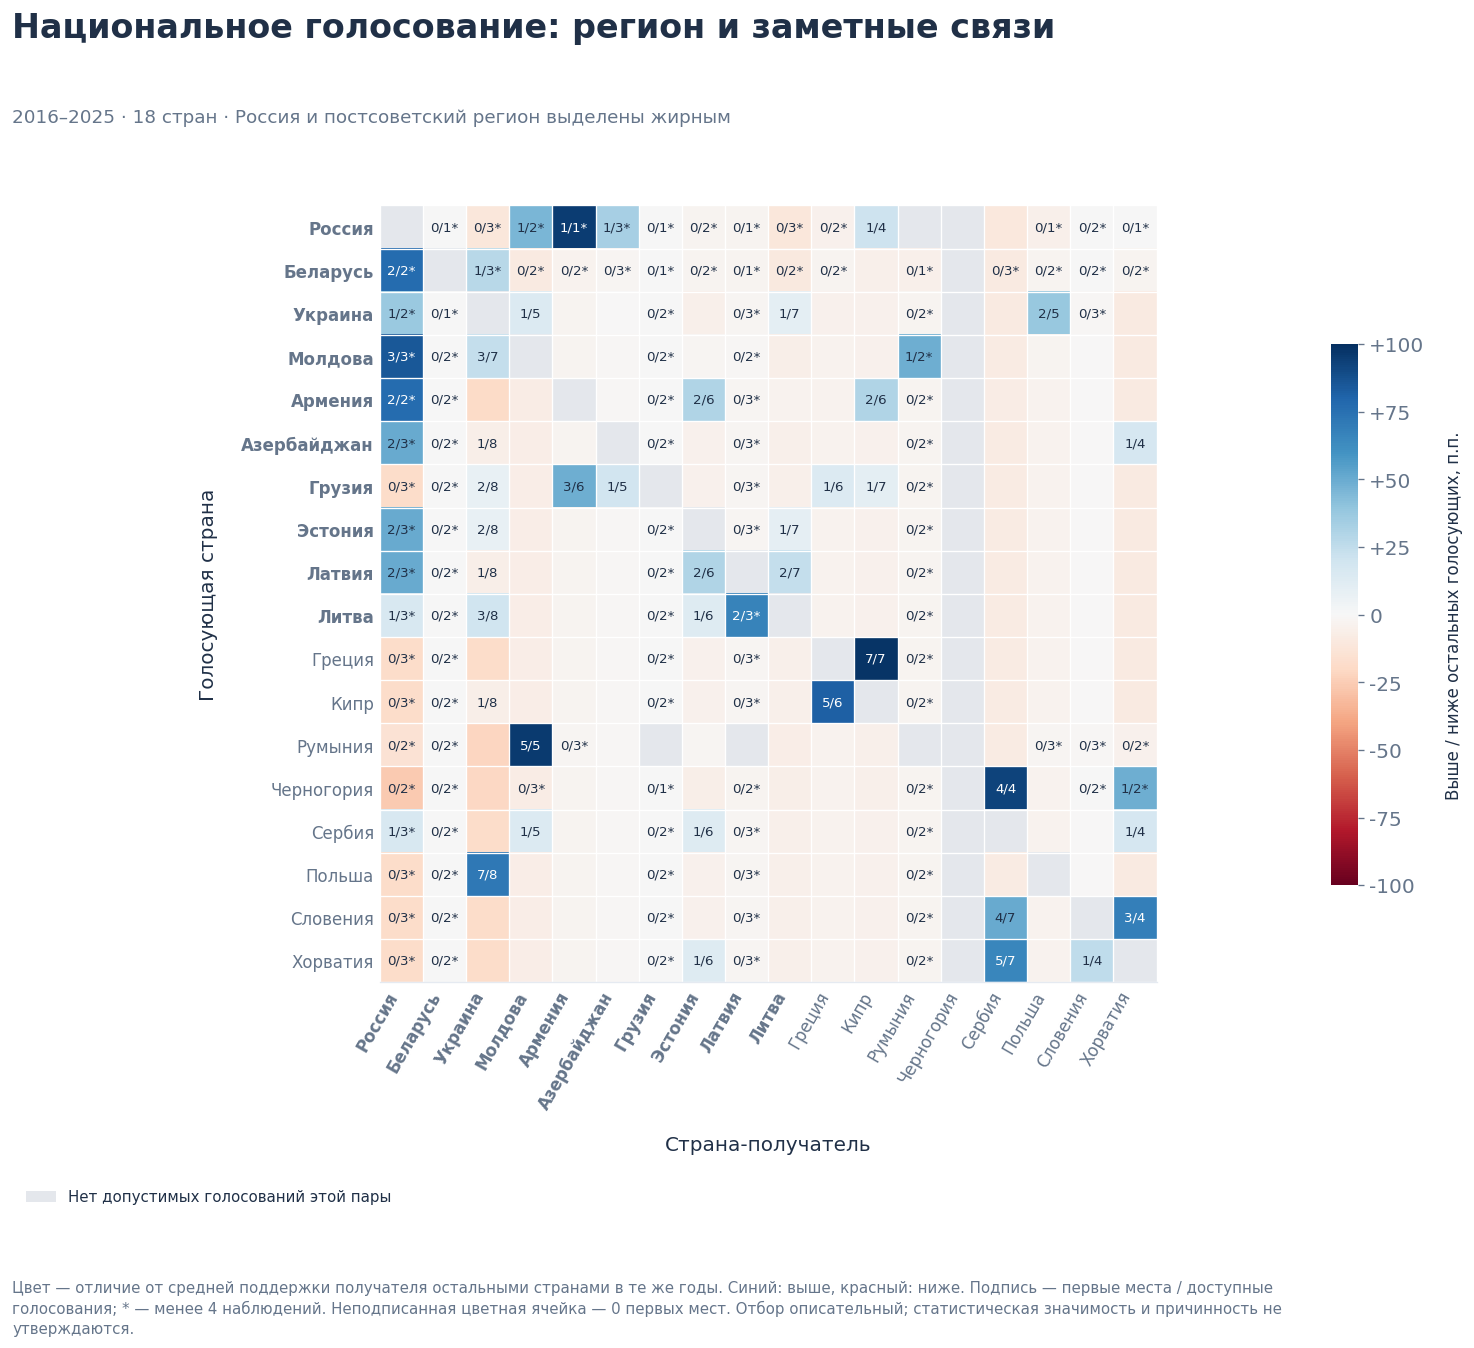

Ядро: Россия, Беларусь, Украина, Молдова, Армения, Азербайджан, Грузия, Эстония, Латвия, Литва
Добавлены по заметным связям: Греция, Кипр, Румыния, Черногория, Сербия, Польша, Словения, Хорватия


In [ ]:
from matplotlib.colors import TwoSlopeNorm
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch

# Обязательное ядро: Россия и постсоветский регион.
FOCUS = ["RU", "BY", "UA", "MD", "AM", "AZ", "GE", "EE", "LV", "LT"]

MAX_COUNTRIES = 18
MIN_YEARS_FOR_SELECTION = 4
MIN_WINS_FOR_SELECTION = 3
LOW_N = 4

data = C.copy()
assert not data.duplicated(["year", "voter", "recipient"]).any()

# Насколько получатель популярен у ОСТАЛЬНЫХ стран в том же году.
# Это описательная статистика для графика, не признак модели.
totals = (
    data.groupby(["year", "recipient"])["target_first_place"]
    .agg(total_wins="sum", total_voters="size")
)

data = data.join(totals, on=["year", "recipient"])
assert (data.total_voters > 1).all()

data["other_support"] = (
    (data.total_wins - data.target_first_place)
    / (data.total_voters - 1)
)

pairs = (
    data.groupby(["voter", "recipient"])
    .agg(
        wins=("target_first_place", "sum"),
        n=("year", "nunique"),
        usual_support=("other_support", "mean"),
    )
    .reset_index()
)

pairs["rate"] = pairs.wins / pairs.n
pairs["excess"] = pairs.rate - pairs.usual_support

# Обязательные страны сохраняем даже при короткой истории.
available = set(data.voter) | set(data.recipient)
countries = [country for country in FOCUS if country in available]

assert MAX_COUNTRIES >= len(countries)

# Добавляем страны из наиболее выраженных повторяющихся связей:
# минимум 4 голосования, 3 первых места и превышение на 20 п.п.
interesting = (
    pairs.loc[
        (pairs.n >= MIN_YEARS_FOR_SELECTION)
        & (pairs.wins >= MIN_WINS_FOR_SELECTION)
        & (pairs.excess >= .20)
    ]
    .sort_values(
        ["excess", "wins", "n", "voter", "recipient"],
        ascending=[False, False, False, True, True],
    )
)

for row in interesting.itertuples():
    additions = [
        country
        for country in (row.voter, row.recipient)
        if country not in countries
    ]

    if len(countries) + len(additions) <= MAX_COUNTRIES:
        countries.extend(additions)

    if len(countries) >= MAX_COUNTRIES:
        break


def pair_matrix(column):
    return (
        pairs.pivot(
            index="voter",
            columns="recipient",
            values=column,
        )
        .reindex(index=countries, columns=countries)
    )


wins = pair_matrix("wins")
counts = pair_matrix("n")
excess = pair_matrix("excess")
values = excess.to_numpy(float)

assert np.isfinite(values).any()

# Синий — поддержка выше, красный — ниже обычной популярности.
cmap = plt.get_cmap("RdBu").copy()
cmap.set_bad("#E4E7EC")

limit = max(.20, np.ceil(np.nanmax(np.abs(values)) * 10) / 10)

side = max(10.5, .42 * len(countries) + 4)
fig, ax = plt.subplots(figsize=(side + 1.3, side))

image = ax.imshow(
    np.ma.masked_invalid(values),
    cmap=cmap,
    norm=TwoSlopeNorm(
        vmin=-limit,
        vcenter=0,
        vmax=limit,
    ),
    interpolation="nearest",
    aspect="equal",
)

labels = [NAMES.get(country, country) for country in countries]

ax.set_xticks(np.arange(len(countries)))
ax.set_xticklabels(
    labels,
    rotation=60,
    ha="right",
    fontsize=10,
)

ax.set_yticks(np.arange(len(countries)))
ax.set_yticklabels(labels, fontsize=10)

# Обязательное ядро выделяем жирным.
for i, country in enumerate(countries):
    if country in FOCUS:
        ax.get_xticklabels()[i].set_fontweight("bold")
        ax.get_yticklabels()[i].set_fontweight("bold")

ax.set_xlabel("Страна-получатель", labelpad=14)
ax.set_ylabel("Голосующая страна", labelpad=14)

ax.set_xticks(
    np.arange(-.5, len(countries), 1),
    minor=True,
)
ax.set_yticks(
    np.arange(-.5, len(countries), 1),
    minor=True,
)

ax.grid(False)
ax.grid(which="minor", color="white", linewidth=.8)
ax.tick_params(which="both", length=0)

# Подписи: первые места / доступные голосования.
# Редкие случаи отмечаем звёздочкой, а не скрываем.
for r in range(len(countries)):
    for c in range(len(countries)):
        if not np.isfinite(values[r, c]):
            continue

        k = int(wins.iloc[r, c])
        n = int(counts.iloc[r, c])

        if k > 0 or n < LOW_N:
            label = f"{k}/{n}" + ("*" if n < LOW_N else "")

            ax.text(
                c, r, label,
                ha="center",
                va="center",
                fontsize=8,
                color=(
                    "white"
                    if abs(values[r, c]) > .58 * limit
                    else INK
                ),
            )

colorbar_axis = fig.add_axes([.89, .35, .017, .39])
colorbar = fig.colorbar(image, cax=colorbar_axis)

colorbar.ax.yaxis.set_major_formatter(
    FuncFormatter(
        lambda x, _: "0" if abs(x) < 1e-9 else f"{100*x:+.0f}"
    )
)
colorbar.set_label(
    "Выше / ниже остальных голосующих, п.п.",
    fontsize=10,
    labelpad=12,
)
colorbar.outline.set_visible(False)

fig.legend(
    handles=[
        Patch(
            facecolor="#E4E7EC",
            label="Нет допустимых голосований этой пары",
        )
    ],
    loc="lower left",
    bbox_to_anchor=(.035, .11),
    frameon=False,
    fontsize=9,
)

finish(
    fig,
    "07_pair_heatmap",
    "Национальное голосование: регион и заметные связи",
    f"{C.year.min()}–{C.year.max()} · {len(countries)} стран · "
    "Россия и постсоветский регион выделены жирным",
    "Цвет — отличие от средней поддержки получателя остальными "
    "странами в те же годы. Синий: выше, красный: ниже. "
    "Подпись — первые места / доступные голосования; "
    f"* — менее {LOW_N} наблюдений. "
    "Неподписанная цветная ячейка — 0 первых мест. "
    "Отбор описательный; статистическая значимость "
    "и причинность не утверждаются.",
    left=.20,
    right=.85,
    top=.84,
    bottom=.28,
)

print(
    "Ядро:",
    ", ".join(
        NAMES.get(country, country)
        for country in countries if country in FOCUS
    ),
)
print(
    "Добавлены по заметным связям:",
    ", ".join(
        NAMES.get(country, country)
        for country in countries if country not in FOCUS
    ),
)

In [ ]:
archive = shutil.make_archive(str(OUT), "zip", OUT)

print(
    f"Сохранено {len(list(OUT.glob('*.png')))} PNG и "
    f"{len(list(OUT.glob('*.pdf')))} PDF."
)

from google.colab import files
files.download(archive)